# Analyze a Parameter Ensemble

In the previous notebook we ran 6 ensemble members, each setting one of 3 FATES parameters to its minimum or maximum value. Together with the default run (`BONA.FATESsp`), that gives the 2N + 1 = 7 runs of a one-at-a-time (OAT) experiment.

In this notebook we will:

1. Load the output of every member, and of the default run
2. Compare each member to the default over time
3. Summarize how sensitive each output is to each parameter

OAT tells us the **direction** and **size** of each parameter's effect around the default. It can't tell us how parameters **interact**, or how the model responds **between** the minimum and maximum (see the [overview](sensitivity_overview.ipynb)).

We will look at four outputs:

| Variable | Description | Units |
|---|---|---|
| `FATES_GPP` | Gross primary production | kg C m<sup>-2</sup> s<sup>-1</sup> (we'll convert to g C m<sup>-2</sup> d<sup>-1</sup>) |
| `EFLX_LH_TOT` | Total latent heat flux| W m<sup>-2</sup> |
| `FCTR` | Canopy transpiration | W m<sup>-2</sup> |
| `FSH` | Sensible heat flux | W m<sup>-2</sup> |
| `FSA` | Absorbed solar radiation | W m<sup>-2</sup> |

<div class="alert alert-warning">
<strong>Note:</strong> Unlike previous notebooks in this section, we will no longer be using the <code>meristem</code> environment as our kernel. Check (or change) your kernel (see upper right corner, above). It should be either <code>NPL 2025a</code> or <code>NPL 2025b</code>.
</div>

In [1]:
from pathlib import Path
import functools
import os
import json

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import seaborn as sns
import pandas as pd
import numpy as np
import xarray as xr

user = os.getenv('USER')
print(f"username is {user}, update to your username if this is not correct")

username is afoster, update to your username if this is not correct


In [111]:
VARIABLES = ["FATES_GPP", "FCTR", "FSH", "FSA", "EFLX_LH_TOT", "FSR"]
YEARS = slice("2014-01-01", "2015-12-31")

## Step 1: Load the manifest

The manifest we wrote at the end of the last notebook has one row per member. For each member it records which parameter was changed and in which direction (from the paramgen key), whether the run finished, and where its output was archived.


In [112]:
manifest = pd.read_csv(f"/glade/u/home/{user}/oat_manifest.csv")
manifest[["member", "parameter", "direction", "run_status", "run_archive_dir"]]

,member,parameter,direction,run_status,run_archive_dir
0,fates_oat_0000,fates_leaf_stomatal_intercept,minimum,done,/glade/derecho/scratch/afoster/oat_ensemble/ar...
1,fates_oat_0001,fates_leaf_stomatal_intercept,maximum,done,/glade/derecho/scratch/afoster/oat_ensemble/ar...
2,fates_oat_0002,fates_leaf_vcmax25top,minimum,done,/glade/derecho/scratch/afoster/oat_ensemble/ar...
3,fates_oat_0003,fates_leaf_vcmax25top,maximum,done,/glade/derecho/scratch/afoster/oat_ensemble/ar...
4,fates_oat_0004,fates_rad_leaf_clumping_index,minimum,done,/glade/derecho/scratch/afoster/oat_ensemble/ar...
5,fates_oat_0005,fates_rad_leaf_clumping_index,maximum,done,/glade/derecho/scratch/afoster/oat_ensemble/ar...


In [92]:
not_done = manifest[manifest["run_status"] != "done"]
if not_done.empty:
    print("All members are done.")
else:
    print("These members haven't finished; see Step 7 of the previous notebook:")
    print(not_done[["member", "run_status"]])

All members are done.


If any members are not done, either wait for them to finish, or if they failed, fix any problems and `retry` (see [previous notebook](submit_ensemble.ipynb)).

---

## Step 2: Load the model output

The functions below open every monthly h0a file for one run, keeps our variables and years, and converts GPP to more readable units.

In [93]:
def preprocess(data_set, variables) -> xr.Dataset:
    """Preprocesses an xarray Dataset by subsetting to specific variables"""
    return data_set[variables]


def load_run(archive_dir, variables=VARIABLES, years=YEARS):
    """Load one run's monthly averaged (h0a) history output as an xarray Dataset."""
    files = sorted(Path(archive_dir, "lnd", "hist").glob("*.clm2.h0a*.nc"))
    ds = xr.open_mfdataset(
        files,
        preprocess=functools.partial(preprocess, variables=variables),
        combine="by_coords",
        decode_timedelta=True,
        )

    ds = ds.sel(time=years)

    # kg C m-2 s-1 -> g C m-2 d-1
    ds["FATES_GPP"] = ds["FATES_GPP"] * 1000 * 86400
    ds["FATES_GPP"].attrs["units"] = "g C m-2 d-1"
    ds["FATES_GPP"].attrs["long_name"] = "gross primary production"
    
    return ds.load().isel(lndgrid=0)

Load every member, and stack them along a new `member` dimension. We also attach each member's `parameter` and `direction`, so we can select members by them later.

In [94]:
ensemble = xr.concat(
    [load_run(d) for d in manifest["run_archive_dir"]],
    dim=pd.Index(manifest["member"], name="member"),
)
ensemble = ensemble.assign_coords(
    parameter=("member", manifest["parameter"].values),
    direction=("member", manifest["direction"].values),
)
ensemble

<xarray.Dataset> Size: 4kB
Dimensions:      (member: 6, time: 24)
Coordinates:
  * time         (time) object 192B 2014-01-16 12:00:00 ... 2015-12-16 12:00:00
  * member       (member) object 48B 'fates_oat_0000' ... 'fates_oat_0005'
    parameter    (member) object 48B 'fates_leaf_stomatal_intercept' ... 'fat...
    direction    (member) object 48B 'minimum' 'maximum' ... 'minimum' 'maximum'
Data variables:
    FATES_GPP    (member, time) float64 1kB 0.0 0.0 0.0 ... 0.004886 0.000101
    FCTR         (member, time) float32 576B 0.0 0.0 0.0 ... 0.01903 0.00264
    FSH          (member, time) float32 576B -8.002 -3.016 ... 16.76 6.647
    FSA          (member, time) float32 576B 0.7134 7.117 26.73 ... 2.85 0.3117
    EFLX_LH_TOT  (member, time) float32 576B -0.9689 0.5456 ... 2.306 -0.1071
    FSR          (member, time) float32 576B 1.709 16.52 56.69 ... 2.487 0.5861
Attributes: (12/36)
    title:                                CLM History file information
    comment:                              NOTE: None of the variables are wei...
    Conventions:                          CF-1.0
    history:                              created on 11/04/26 09:45:25
    source:                               Community Terrestrial Systems Model
    hostname:                             derecho
    ...                                   ...
    ctype_urban_roof:                     71
    ctype_urban_sunwall:                  72
    ctype_urban_shadewall:                73
    ctype_urban_impervious_road:          74
    ctype_urban_pervious_road:            75
    time_period_freq:                     month_1

Now load the default run:

In [95]:
default_archive = f"/glade/derecho/scratch/{user}/archive/BONA.FATESsp"
default = load_run(default_archive)
default

<xarray.Dataset> Size: 864B
Dimensions:      (time: 24)
Coordinates:
  * time         (time) object 192B 2014-01-16 12:00:00 ... 2015-12-16 12:00:00
Data variables:
    FATES_GPP    (time) float64 192B 0.0 0.0 0.0 ... 0.1725 0.004929 0.0001021
    FCTR         (time) float32 96B 0.0 0.0 0.0 ... 0.2273 0.01917 0.002662
    FSH          (time) float32 96B -8.002 -3.016 -5.264 ... 7.266 16.72 6.623
    FSA          (time) float32 96B 0.7134 7.117 26.73 ... 19.66 2.865 0.3037
    EFLX_LH_TOT  (time) float32 96B -0.9689 0.5456 1.604 ... 3.877 2.34 -0.09919
    FSR          (time) float32 96B 1.709 16.52 56.69 ... 8.728 2.471 0.5941
Attributes: (12/36)
    title:                                CLM History file information
    comment:                              NOTE: None of the variables are wei...
    Conventions:                          CF-1.0
    history:                              created on 10/29/26 15:19:43
    source:                               Community Terrestrial Systems Model
    hostname:                             derecho
    ...                                   ...
    ctype_urban_roof:                     71
    ctype_urban_sunwall:                  72
    ctype_urban_shadewall:                73
    ctype_urban_impervious_road:          74
    ctype_urban_pervious_road:            75
    time_period_freq:                     month_1

<div class="alert alert-warning">
  <strong>Important Note:</strong> Remember that these cases (the base case and every OAT member) used <code>CLM_FORCE_COLDSTART=on</code>. So in our first two years (2014-2015), soil moisture and soil temperature are still spinning up. The comparison is still fair, because every member and the default go through the same transient states. Each difference is still caused by its parameter. However, the absolute values for 2014–2015 aren't equilibrium values. Thus, effects that work through soil water, like stomatal conductance under drying soils, may be muted or exaggerated compared with a spun-up run.
</div>

<div class="alert alert-info">
How would you fix this?
</details>
</div>

<div class="alert alert-success">
<details>
<summary><font face="Times New Roman" color='blue'>Click here for the solution</font></summary><br>
Spin the model up first (~60 years for SP mode) and start the OAT members from that restart (<code>finidat= ...</code>; <code>CLM_FORCE_COLDSTART=off</code>).
</details>
</div>

---

## Step 3: Compare each member to the default

Each member changes only one parameter, so any difference from the default run is caused by that parameter. Plot, for each parameter, the default run along with its minimum and maximum members.

### Grab the correct data arrays

This helper function gives a member name given its parameter and direction:

In [96]:
def get_member(manifest, parameter, direction):
    """Name of the member that set `parameter` to its `direction` ('minimum' or 'maximum')."""
    rows = manifest[(manifest["parameter"] == parameter) & (manifest["direction"] == direction)]
    return rows["member"].item()

First we will pick a parameter and variable and pull out the minimum, maximum, and default data arrays for that variable:

In [97]:
var = "FATES_GPP"
param = "fates_leaf_vcmax25top"

lo = ensemble[var].sel(member=get_member(manifest, param, "minimum"))
hi = ensemble[var].sel(member=get_member(manifest, param, "maximum"))
base = default[var]

lo

<xarray.DataArray 'FATES_GPP' (time: 24)> Size: 192B
array([0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 1.46024603e-01,
       1.28022261e+00, 4.05945514e+00, 4.16881100e+00, 1.69928843e+00,
       4.65496314e-01, 7.34432653e-02, 0.00000000e+00, 0.00000000e+00,
       6.61530271e-05, 1.65991438e-04, 1.67648594e-02, 1.28097598e-01,
       1.36446655e+00, 4.27923744e+00, 4.13162332e+00, 1.76634481e+00,
       5.56234489e-01, 7.64342296e-02, 1.85126722e-03, 3.54904945e-05])
Coordinates:
  * time       (time) object 192B 2014-01-16 12:00:00 ... 2015-12-16 12:00:00
    member     <U14 56B 'fates_oat_0002'
    parameter  object 8B 'fates_leaf_vcmax25top'
    direction  object 8B 'minimum'
Attributes:
    units:      g C m-2 d-1
    long_name:  gross primary production

### Plot the time series

Next we will plot them next to each other:

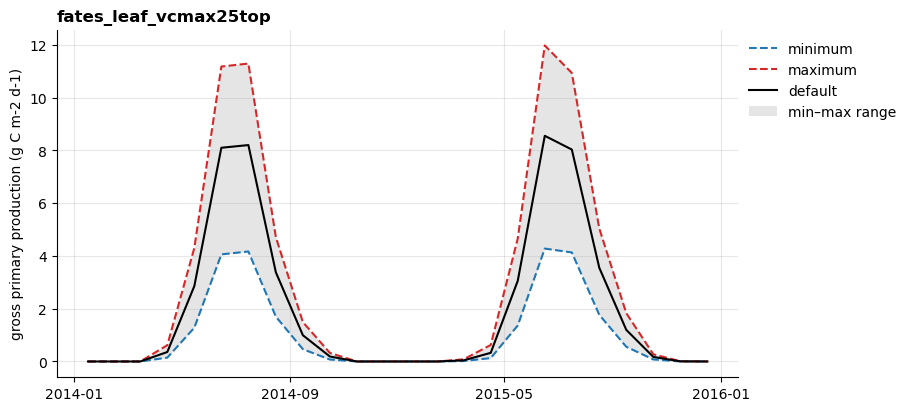

In [98]:
fig, ax = plt.subplots(figsize=(9, 4), constrained_layout=True)

# the two min/max members, plus the default
lo.plot(ax=ax, color="tab:blue", lw=1.5, ls="--", label="minimum")
hi.plot(ax=ax, color="tab:red", lw=1.5, ls="--", label="maximum")
base.plot(ax=ax, color="k", lw=1.5, label="default")

# shaded envelope between min and max
ax.fill_between(base["time"].values, lo, hi, color="tab:gray", alpha=0.2,
                linewidth=0, label="min–max range")

units = lo.attrs.get("units", "")
long_name = lo.attrs.get("long_name", var)
ax.set_title(param, loc="left", fontweight="bold")
ax.set_xlabel("")
ax.set_ylabel(f"{long_name} ({units})" if units else var)
ax.grid(alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, ncol=1, loc="upper right", bbox_to_anchor=(1.25, 1.0));

Let's turn that code into helper functions so we can explore more parameters and variables:

In [99]:
def plot_time_series(ensemble, default, variable, parameter, manifest):
    """Plot the minimum, maximum, and default values for a given OAT parameter"""

    # get the correct data arrays
    lo = ensemble[variable].sel(member=get_member(manifest, parameter, "minimum"))
    hi = ensemble[variable].sel(member=get_member(manifest, parameter, "maximum"))
    base = default[variable]

    fig, ax = plt.subplots(figsize=(9, 4), constrained_layout=True)
    
    # shaded envelope between min and max
    ax.fill_between(base["time"].values, lo, hi, color="tab:gray", alpha=0.2, linewidth=0, label="min–max range")
    
    # the two min/max members, plus the default
    lo.plot(ax=ax, color="tab:blue", lw=1.5, ls="--", label="minimum")
    hi.plot(ax=ax, color="tab:red", lw=1.5, ls="--", label="maximum")
    base.plot(ax=ax, color="k", lw=1.5, label="default")
    
    units = lo.attrs.get("units", "")
    long_name = lo.attrs.get("long_name", variable)
    ax.set_title(parameter, loc="left", fontweight="bold")
    ax.set_xlabel("")
    ax.set_ylabel(f"{long_name} ({units})" if units else variable)
    ax.grid(alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(frameon=False, ncol=1, loc="upper right", bbox_to_anchor=(1.25, 1.0));

We will use this helper function to explore parameter sensitivity.

In [100]:
parameters = manifest.parameter.unique()
variables = list(ensemble.data_vars)

print(f"Available parameters are: {', '.join(parameters)}")
print("--------")
print(f"Available variables are: {', '.join(variables)}")

Available parameters are: fates_leaf_stomatal_intercept, fates_leaf_vcmax25top, fates_rad_leaf_clumping_index
--------
Available variables are: FATES_GPP, FCTR, FSH, FSA, EFLX_LH_TOT, FSR


### Explore

Update the variable and parameter for the below function to explore:

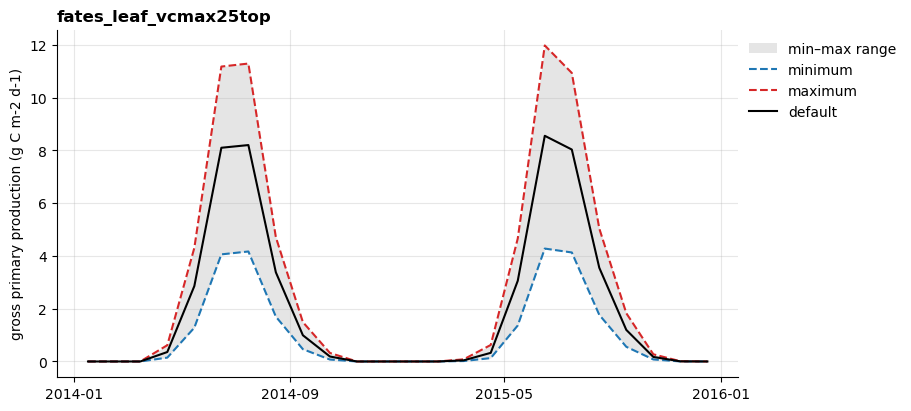

In [101]:
plot_time_series(ensemble, default, 'FATES_GPP', 'fates_leaf_vcmax25top', manifest)

<div class="alert alert-info">
<strong>Interpretation exercise 1</strong><br><br>

Why is FSA almost insensitive to vcmax25top and stomatal_intercept, but sensitive to clumping index?


<em>Hint:</em> FSA is absorbed solar radiation. What kinds of things affect this? Remember that we are in SP (satellite phenology) mode.
</div>

<div class="alert alert-success">
<details>
<summary><font face="Times New Roman" color='blue'>Click here for the solution</font></summary><br>

In this configuration of FATES, only clumping index (of the 3 parameters) changes how much radiation the canopy absorbs. In FATES-SP mode, LAI is prescribed, so there is no structural feedback from GPP to absorbed light.
</details>
</div>

<div class="alert alert-info">
<strong>Interpretation exercise 2</strong><br><br>

When FCTR goes up, what happens to FSH, and why?

<em>Hint:</em> FCTR = canopy transpiration; FSH = sensible heat flux
</div>

<div class="alert alert-success">
<details>
<summary><font face="Times New Roman" color='blue'>Click here for the solution</font></summary><br>
This correlation is due to energy partitioning. When canopy transpiration (and thus latent heat) increases, sensible heat decreases.
</details>
</div>

---

## Step 4: When in the year does each parameter matter?

Let's also take the difference of each member from the default run directly to better investigate *where* in the seasonal cycle each parameter matters most.

We can calculate <code>ensemble[var] - default[var]</code> directly because xarray broadcasts across each `member` automatically (the time coordinates all match up). Do this below:

In [102]:
var = 'FATES_GPP'
diff = ensemble[var] - default[var]
diff

<xarray.DataArray 'FATES_GPP' (member: 6, time: 24)> Size: 1kB
array([[ 0.00000000e+00,  0.00000000e+00,  0.00000000e+00,
         0.00000000e+00,  0.00000000e+00,  0.00000000e+00,
         0.00000000e+00,  0.00000000e+00,  0.00000000e+00,
         0.00000000e+00,  0.00000000e+00,  0.00000000e+00,
         0.00000000e+00,  0.00000000e+00,  0.00000000e+00,
         0.00000000e+00,  0.00000000e+00,  0.00000000e+00,
         0.00000000e+00,  0.00000000e+00,  0.00000000e+00,
         0.00000000e+00,  0.00000000e+00,  0.00000000e+00],
       [ 0.00000000e+00,  0.00000000e+00,  0.00000000e+00,
         5.10567916e-03,  2.81006447e-02,  1.49970897e-01,
         1.61422882e-01,  3.02986940e-02,  8.87667120e-03,
         9.73374699e-03,  0.00000000e+00,  0.00000000e+00,
        -8.36046988e-05, -1.13973631e-05, -1.03437760e-03,
         3.30907715e-03,  5.75116952e-02,  2.54539959e-01,
         1.48185552e-01,  4.62439028e-02,  1.89549930e-02,
         9.90073022e-04, -5.12012321e-05, -5.71328584e-07],
       [ 0.00000000e+00,  0.00000000e+00,  0.00000000e+00,
        -2.12328436e-01, -1.57721701e+00, -4.04063609e+00,
        -4.03313041e+00, -1.68000733e+00, -5.28503761e-01,
        -1.14790621e-01,  0.00000000e+00,  0.00000000e+00,
...
        -4.09827228e-05, -1.13973631e-05,  3.85367428e-02,
         2.98140910e-01,  1.60167388e+00,  3.42357012e+00,
         2.90247495e+00,  1.48932348e+00,  6.31945391e-01,
         1.00046920e-01,  4.13018524e-03,  9.79633462e-05],
       [ 0.00000000e+00,  0.00000000e+00,  0.00000000e+00,
        -4.40348129e-02, -7.44250137e-03,  1.96721172e-02,
         2.39594607e-02,  5.25325304e-03, -1.81221985e-03,
         4.70794475e-04,  0.00000000e+00,  0.00000000e+00,
        -3.95088762e-07, -6.53574215e-06, -7.55206202e-04,
         6.72602546e-03, -2.57620937e-02,  1.64974714e-02,
         2.38136156e-02,  3.34500801e-03, -1.35024602e-03,
        -4.82738687e-04, -1.23211521e-06,  5.35347766e-07],
       [ 0.00000000e+00,  0.00000000e+00,  0.00000000e+00,
        -1.87410580e-02, -6.98579242e-01,  1.35078980e-01,
         2.51299934e-02,  3.10320058e-02,  2.38452049e-03,
        -1.48684812e-02,  0.00000000e+00,  0.00000000e+00,
         2.42732874e-05,  1.27223224e-04, -9.97484130e-04,
         1.23225960e-02,  3.06340749e-02,  4.06386098e-02,
         2.46497104e-02,  2.67949537e-02,  3.89467750e-03,
         7.80243863e-04, -4.30169052e-05, -1.03713198e-06]])
Coordinates:
  * time       (time) object 192B 2014-01-16 12:00:00 ... 2015-12-16 12:00:00
  * member     (member) object 48B 'fates_oat_0000' ... 'fates_oat_0005'
    parameter  (member) object 48B 'fates_leaf_stomatal_intercept' ... 'fates...
    direction  (member) object 48B 'minimum' 'maximum' ... 'minimum' 'maximum'

Now calculate monthly climatology with `.groupby("time.month").mean()` on that difference:

In [103]:
climo = diff.groupby("time.month").mean()
climo

<xarray.DataArray 'FATES_GPP' (member: 6, month: 12)> Size: 576B
array([[ 0.00000000e+00,  0.00000000e+00,  0.00000000e+00,
         0.00000000e+00,  0.00000000e+00,  0.00000000e+00,
         0.00000000e+00,  0.00000000e+00,  0.00000000e+00,
         0.00000000e+00,  0.00000000e+00,  0.00000000e+00],
       [-4.18023494e-05, -5.69868153e-06, -5.17188801e-04,
         4.20737815e-03,  4.28061699e-02,  2.02255428e-01,
         1.54804217e-01,  3.82712984e-02,  1.39158321e-02,
         5.36191001e-03, -2.56006160e-05, -2.85664292e-07],
       [-1.48633657e-05,  7.72970376e-05, -1.31066688e-02,
        -2.05844487e-01, -1.63553769e+00, -4.15734298e+00,
        -3.96713502e+00, -1.73264767e+00, -5.84455224e-01,
        -1.05435179e-01, -1.53905264e-03, -3.32941910e-05],
       [-2.04913614e-05, -5.69868153e-06,  1.92683714e-02,
         2.78004177e-01,  1.52466342e+00,  3.25033944e+00,
         2.99598839e+00,  1.41105102e+00,  5.65166402e-01,
         1.17649575e-01,  2.06509262e-03,  4.89816731e-05],
       [-1.97544381e-07, -3.26787107e-06, -3.77603101e-04,
        -1.86543937e-02, -1.66022975e-02,  1.80847943e-02,
         2.38865381e-02,  4.29913052e-03, -1.58123294e-03,
        -5.97210601e-06, -6.16057605e-07,  2.67673883e-07],
       [ 1.21366437e-05,  6.36116120e-05, -4.98742065e-04,
        -3.20923100e-03, -3.33972584e-01,  8.78587947e-02,
         2.48898519e-02,  2.89134798e-02,  3.13959899e-03,
        -7.04411868e-03, -2.15084526e-05, -5.18565990e-07]])
Coordinates:
  * member     (member) object 48B 'fates_oat_0000' ... 'fates_oat_0005'
    parameter  (member) object 48B 'fates_leaf_stomatal_intercept' ... 'fates...
    direction  (member) object 48B 'minimum' 'maximum' ... 'minimum' 'maximum'
  * month      (month) int64 96B 1 2 3 4 5 6 7 8 9 10 11 12

Now let's do this calculation across all the variables and plot the output, a helper function for this is below:

In [105]:
def plot_seasonal_diff(ensemble, default, manifest, parameters, variables):
    
    colors = dict(zip(parameters, plt.cm.tab10.colors))

    fig, axes = plt.subplots(3, 2, figsize=(12, 7), sharex=True, layout="constrained")
    for ax, var in zip(axes.flat, variables):
        diff = ensemble[var] - default[var]
        climo = diff.groupby("time.month").mean()
        for param in parameters:
            ax.plot(climo.month, climo.sel(member=get_member(manifest, param, 'maximum')), color=colors[param], ls="-", label=param)
            ax.plot(climo.month, climo.sel(member=get_member(manifest, param, 'minimum')), color=colors[param], ls="--")
    
        ax.axhline(0, color="k", lw=0.8)
        ax.set_xticks(range(1, 13), list("JFMAMJJASOND"))
        ax.set_ylabel(f"Δ {var} ({default[var].attrs['units']})")
    
    handles, labels = axes.flat[0].get_legend_handles_labels()
    handles += [Line2D([], [], color="k", ls="-"), Line2D([], [], color="k", ls="--")]
    labels += ["maximum", "minimum"]
    fig.legend(handles, labels, loc="outside right center")

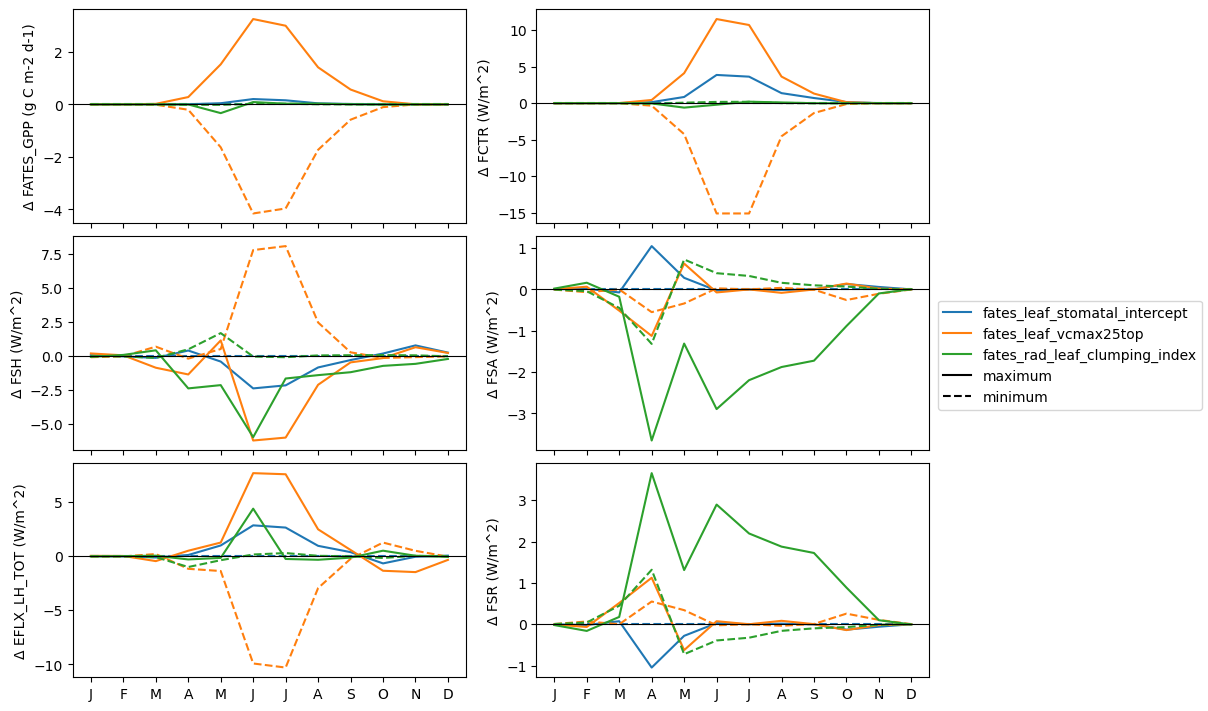

In [106]:
plot_seasonal_diff(ensemble, default, manifest, parameters, variables)

<div class="alert alert-info">
<strong>Interpretation exercise 3</strong><br><br>

In which months does each parameter change GPP and FCTR? How might only looking at an annual mean (see below) understate these effects at a boreal site?
</div>

<div class="alert alert-success">
<details>
<summary><font face="Times New Roman" color='blue'>Click here for the solution</font></summary><br>

<strong>When do the parameters matter?</strong> Almost all of the differences happen between April and October. From November to March the canopy is mostly inactive and the site is snow-covered, so changing a photosynthesis or stomatal parameter has a much lower effect. The differences grow in May, peak in June–July, and fade by October.

<ul>
<li><strong>GPP and FCTR</strong> respond most to <code>fates_leaf_vcmax25top</code>.
<li><strong>FSA</strong> responds mostly to <code>fates_rad_leaf_clumping_index</code>. In summer, a less-clumped canopy (maximum value) puts more of the light onto leaves, which reflect more than the dark ground below, so the surface absorbs less. In spring, the FSA differences for all parameters come from changes in snow cover and melt timing.
</ul>

<strong>Why does an annual mean understate these effects?</strong> At a boreal site like BONA, about half the year contributes much less to the difference. Averaging those near-zero months with the growing season dilutes the signal. A parameter that changes summer canopy transpiration may change mean annual transpiration by much less. Always check <em>when</em> a parameter matters, not just how much it matters on average.

<em>Note:</em> each month here is an average of only two years, so treat single-month spikes (especially in spring) with caution.

</details>
</div>

## Step 5. Look at sensitivity of annual variables

Next we will calculate annual sums or means of our variables and investigate parameter sensitivity of annual metrics.

Below is a helper function for calculating annual means and sums.

In [113]:
def annual_metric(data_array, how, conversion_factor=None):
    """Calculates annual mean or sum of an input DataArray, applies a 
    conversion factor if supplied
    """
    if conversion_factor is not None:
        data_array = data_array * conversion_factor

    months = data_array["time.daysinmonth"]
    annual_sum = (months * data_array).groupby("time.year").sum()
    units = data_array.attrs["units"]

    if how == 'mean':
        annual_mean = annual_sum / 365.0
        annual_mean.attrs["units"] = units
        return annual_mean
    elif how == 'sum':
        annual_sum.attrs["units"] = units.replace("d", "yr")
        return annual_sum
        
    raise ValueError(
        f"`how` must be 'mean' or 'sum', not {how}"
    )


variable_dict = {
    'FATES_GPP': 'sum',
    'FCTR': 'mean',
    'FSH': 'mean',
    'FSA': 'mean',
    'EFLX_LH_TOT': 'mean',
    'SNOW_DEPTH': 'mean',
    'FSR': 'mean',
}

### Dot plots

First let's look at one variable and for every parameter plot the value at the minimum, maximum, and default:

In [108]:
variable = 'FATES_GPP'
ann_var = annual_metric(ensemble[variable], variable_dict[variable])
ann_default = annual_metric(default[variable], variable_dict[variable])

dfs = []
for parameter in parameters:
    param_values = {}
    param_values['low'] = ann_var.sel(member=get_member(manifest, parameter, "minimum")).mean(dim='year').values
    param_values['high'] = ann_var.sel(member=get_member(manifest, parameter, "maximum")).mean(dim='year').values
    dfs.append(pd.DataFrame(param_values, index=[parameter]))
var_df = pd.concat(dfs)


var_df

,low,high
fates_leaf_stomatal_intercept,750.044048,764.115693
fates_leaf_vcmax25top,370.499537,1061.039268
fates_rad_leaf_clumping_index,750.326608,743.760143


Now we can plot these minimum, maximum, and default:

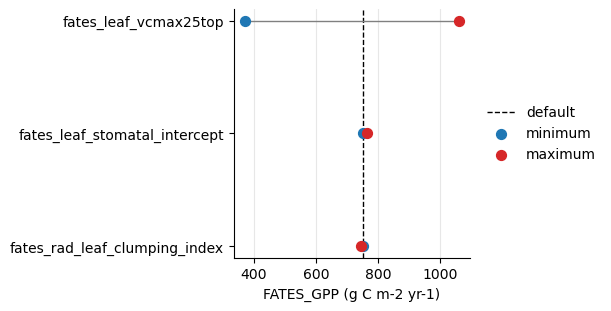

In [109]:
fig, ax = plt.subplots(figsize=(6, 3), constrained_layout=True)

# sort by difference
var_df['diff'] = np.abs(var_df['high'] - var_df['low'])
var_df = var_df.sort_values(by='diff')
y = np.arange(len(var_df))

# plot default down the middle
ax.axvline(ann_default.mean(dim='year').values, color="k", lw=1,
           label="default", linestyle='dashed')

# plot min, max, and line in between
ax.scatter(var_df["low"], y, color="tab:blue", s=50, zorder=3, label="minimum")
ax.scatter(var_df["high"], y, color="tab:red", s=50, zorder=3, label="maximum")
ax.hlines(y, var_df["low"], var_df["high"], color="gray", lw=1, zorder=2)

ax.set_yticks(y, var_df.index)
units = ann_var.units
ax.set_xlabel(f"{variable} ({units})")
ax.grid(axis="x", alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="center left", bbox_to_anchor=(1.02, 0.5));

<div class="alert alert-info">
<strong>Interpretation exercise 4</strong><br><br>

Which parameter matters most for annual GPP? Is the response symmetric around the default?


<em>Hint:</em> Compare how far the minimum and maximum points sit from the default line. Then compare that to how far each parameter's minimum and maximum <em>values</em> are from its default (see <code>main.csv</code>, <code>fates_leaf_vcmax25top.csv</code>, and the default parameter file). Look closely at the <code>fates_leaf_stomatal_intercept</code> minimum.
</div>

<div class="alert alert-success">
<details>
<summary><font face="Times New Roman" color='blue'>Click here for the solution</font></summary><br>

<code>fates_leaf_vcmax25top</code> dominates. The other two parameters change annual GPP by only a small amount.<br><br>

The vcmax response is <strong>not symmetric</strong>, and the asymmetry is the opposite of what the parameter range would suggest. For the dominant PFT at BONA (needleleaf evergreen tree), the default vcmax25top is 62 μmol m<sup>-2</sup> s<sup>-1</sup> and the OAT range is ~22–129, so the maximum is <em>further</em> from the default than the minimum. Even so, the minimum changes GPP more.

<code>fates_leaf_stomatal_intercept</code> is asymmetric for a different reason: its minimum (10000)
<em>is</em> the default for every PFT that grows at BONA, so the "minimum" member is identical to the default run. When an OAT range isn't centered on the default, always check where the default sits.<br><br>

</details>
</div>

### Plotting a heatmap

Next we will loop through each variable and parameter and calculate parameter sensitivity for as: `abs(hi_value - lo_value)/default`.

In [114]:
dfs = []
for variable in variables:
    
    # calculate annual metric
    ann_var = annual_metric(ensemble[variable], variable_dict[variable])
    ann_default = annual_metric(default[variable], variable_dict[variable])
    
    sensitivity = {}
    for parameter in parameters:
        annual_lo = ann_var.sel(member=get_member(manifest, parameter, "minimum"))
        annual_hi = ann_var.sel(member=get_member(manifest, parameter, "maximum"))
        sensitivity[parameter] = (np.abs(annual_hi - annual_lo)/ann_default).mean(dim='year').values
    dfs.append(pd.DataFrame(sensitivity, index=[variable]))
    
sens_df = pd.concat(dfs)

sens_df

,fates_leaf_stomatal_intercept,fates_leaf_vcmax25top,fates_rad_leaf_clumping_index
FATES_GPP,0.018720,0.920564,0.013691
FCTR,0.123303,0.834566,0.018747
FSH,0.055099,0.447368,0.264601
FSA,0.001599,0.001319,0.016805
EFLX_LH_TOT,0.024175,0.137349,0.030953
FSR,0.004538,0.003416,0.045829


We can then plot a heatmap of these sensitivity values:

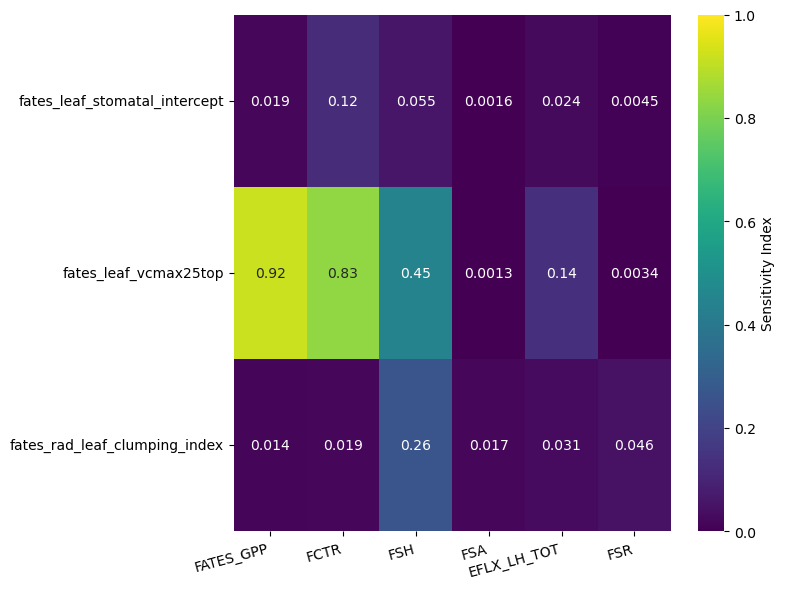

In [115]:
plt.figure(figsize=(8, 6))
sns.heatmap(
    sens_df.T, 
    annot=True, 
    cmap="viridis", 
    cbar=True,
    cbar_kws={'label': 'Sensitivity Index'},
    vmin=0,
    vmax=1
)
plt.xticks(rotation=15, ha="right")
plt.yticks(rotation=0)
plt.tight_layout();

## Step 6: Response vs. parameter value

So far we have plotted which member changed what. Now let's plot model output against the actual **value** of each parameter. With OAT we have three points per parameter: minimum, default, and maximum.

The minimum, maximum, and default values come from the same files we used to build the ensemble in [create_param_ensembles](create_param_ensembles.ipynb).

In [116]:
meristem_dir = Path(f"/glade/u/home/{user}/code/meristem")
fates_example_dir = meristem_dir / "examples/paramgen/fates_example"
param_dir = fates_example_dir / "fates_param_dir"

main_df = pd.read_csv(param_dir / "main.csv", index_col=0)

with open(fates_example_dir / "default_fates_param.json", encoding="utf-8") as f:
    default_params = json.load(f)["parameters"]

The below helper function lets us read in the parameter values for the mininum, maximum, and default members:

In [117]:
def get_param_values(parameter, pft):
    """Return (minimum, default, maximum) of `parameter` for one PFT (1-based index)."""

    # default value; vcmax25top has an extra leaf-age dimension, so index the last axis
    default_value = np.array(default_params[parameter]["data"])[..., pft - 1].item()

    param_min = main_df.loc[parameter, "param_min"]
    param_max = main_df.loc[parameter, "param_max"]

    # PFT-specific ranges live in their own csv file
    if param_min == "pft":
        pft_df = pd.read_csv(param_dir / f"{parameter}.csv", index_col=0, encoding="utf-8-sig")
        param_min = pft_df.loc[pft, "param_min"]
        param_max = pft_df.loc[pft, "param_max"]

    return float(param_min), float(default_value), float(param_max)

Total GPP at BONA comes from several PFTs, and each PFT has its own default and range for some parameters (i.e. `fates_leaf_vcmax25top`). To see how GPP responds to a parameter's *value*, we can look at each PFT's GPP against **that PFT's own** parameter value.

FATES writes PFT-level GPP to `FATES_GPP_PF`. Let's load it for every member and the default run:

In [66]:
def load_gpp_pf(archive_dir, years=YEARS):
    """Load one run's monthly PFT-level GPP (FATES_GPP_PF) in g C m-2 d-1."""
    files = sorted(Path(archive_dir, "lnd", "hist").glob("*.clm2.h0a*.nc"))
    ds = xr.open_mfdataset(
        files,
        preprocess=functools.partial(preprocess, variables=["FATES_GPP_PF"]),
        combine="by_coords",
        decode_timedelta=True,
    )
    gpp_pf = ds["FATES_GPP_PF"].sel(time=years).load().isel(lndgrid=0)

    # kg C m-2 s-1 -> g C m-2 d-1
    gpp_pf = gpp_pf * 1000 * 86400
    gpp_pf.attrs["units"] = "g C m-2 d-1"

    # label PFTs 1, 2, ... to match the parameter files
    return gpp_pf.assign_coords(fates_levpft=np.arange(1, gpp_pf.sizes["fates_levpft"] + 1))


ensemble_gpp_pf = xr.concat(
    [load_gpp_pf(d) for d in manifest["run_archive_dir"]],
    dim=pd.Index(manifest["member"], name="member"),
)
default_gpp_pf = load_gpp_pf(default_archive)

Which PFTs actually grow at BONA? Calculate each PFT's annual GPP in the default run:

In [68]:
pft_names = pd.read_csv(param_dir / "fates_leaf_vcmax25top.csv", index_col=0, encoding="utf-8-sig")["pft_name"]

ann_default_pf = annual_metric(default_gpp_pf, "sum").mean("year").to_series()
ann_default_pf.index = pft_names.loc[ann_default_pf.index] + " (" + ann_default_pf.index.astype(str) + ")"
ann_default_pf.round(1)

broadleaf_evergreen_tropical_tree (1)         0.0
needleleaf_evergreen_extratrop_tree (2)     383.4
needleleaf_colddecid_extratrop_tree (3)       0.0
broadleaf_evergreen_extratrop_tree (4)        0.0
broadleaf_hydrodecid_tropical_tree (5)        0.0
broadleaf_colddecid_extratrop_tree (6)        0.0
broadleaf_evergreen_extratrop_shrub (7)       0.0
broadleaf_hydrodecid_extratrop_shrub (8)      0.0
broadleaf_colddecid_extratrop_shrub (9)      11.6
broadleaf_evergreen_arctic_shrub (10)         0.0
broadleaf_colddecid_arctic_shrub (11)        92.4
arctic_c3_grass (12)                        262.7
cool_c3_grass (13)                            0.0
c4_grass (14)                                 0.0
dtype: float64

At BONA we see that there are 4 PFTS: needleleaf evergreen trees, arctic C3 grasses, deciduous arctic shrubs, and deciduous extratropical shrubs.

We will subset to just these PFTs:

In [69]:
ann_pf = annual_metric(default_gpp_pf, "sum").mean("year")
active_pfts = [int(p) for p in ann_pf.fates_levpft if ann_pf.sel(fates_levpft=p) > 0.0 * ann_pf.sum()]

Now plot each PFT's annual GPP against its own parameter value. The dotted lines connect the minimum and maximum members directly: this is what you would assume if the response were linear.

In [76]:
def plot_gpp_pf_response(ensemble_gpp_pf, default_gpp_pf, manifest, parameters, pfts):
    """Plot annual PFT-level GPP vs. each PFT's own parameter value (min, default, max)."""

    ann_members = annual_metric(ensemble_gpp_pf, "sum").mean("year")
    ann_default = annual_metric(default_gpp_pf, "sum")
    units = ann_default.attrs["units"]
    ann_default = ann_default.mean("year")

    colors = dict(zip(pfts, plt.cm.tab10.colors))
    markers = {"minimum": "v", "default": "o", "maximum": "^"}

    fig, axes = plt.subplots(1, len(parameters), figsize=(4.5 * len(parameters), 4),
                             sharey=True, layout="constrained")

    for ax, parameter in zip(axes, parameters):
        lo = ann_members.sel(member=get_member(manifest, parameter, "minimum"))
        hi = ann_members.sel(member=get_member(manifest, parameter, "maximum"))

        for pft in pfts:
            x = get_param_values(parameter, pft)
            y = [float(da.sel(fates_levpft=pft)) for da in (lo, ann_default, hi)]

            # straight line from minimum to maximum
            ax.plot([x[0], x[2]], [y[0], y[2]], color=colors[pft], ls=":", lw=1.5)

            # the three OAT points, connected in order of parameter value
            order = np.argsort(x)
            ax.plot(np.array(x)[order], np.array(y)[order], color=colors[pft], lw=1)
            for xi, yi, direction in zip(x, y, markers):
                ax.scatter(xi, yi, color=colors[pft], marker=markers[direction], s=60, zorder=3)

        ax.set_title(parameter, fontsize=10, fontweight="bold")
        ax.set_xlabel("parameter value (PFT-specific)")
        ax.grid(alpha=0.3)
        ax.spines[["top", "right"]].set_visible(False)

    axes[0].set_ylabel(f"PFT GPP ({units})")

    # legend: colors for PFTs, marker shapes for members
    handles = [plt.Line2D([], [], color=colors[p], lw=2, label=f"{pft_names.loc[p]} ({p})") for p in pfts]
    handles += [plt.Line2D([], [], color="gray", marker=m, ls="", label=d) for d, m in markers.items()]
    handles += [plt.Line2D([], [], color="gray", ls=":", label="straight line (min to max)")]
    fig.legend(handles=handles, loc="outside right center", frameon=False)

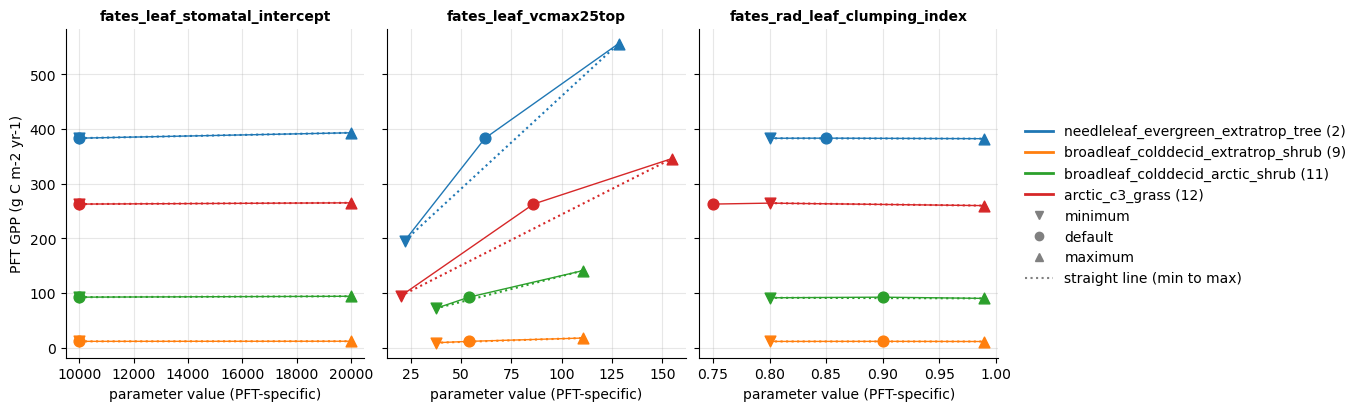

In [77]:
plot_gpp_pf_response(ensemble_gpp_pf, default_gpp_pf, manifest, parameters, active_pfts)

<div class="alert alert-info">
<strong>Interpretation exercise 5</strong><br><br>

Suppose you only had the minimum and maximum runs for <code>fates_leaf_vcmax25top</code> and assumed GPP changes linearly between them. For each PFT, would you over- or underestimate GPP at the default value? What does that tell you about the shape of the response?
</div>

<div class="alert alert-success">
<details>
<summary><font face="Times New Roman" color='blue'>Click here for the solution</font></summary><br>

For almost every PFT the default point sits <strong>above</strong> the dotted line, so a linear assumption underestimates GPP at the default.<br><br>


Three points are enough to show that the response <em>bends</em>, but not <em>where</em> or <em>how sharply</em>.
</details>
</div>

<div class="alert alert-info">
<strong>Interpretation exercise 6 </strong><br><br>

Look at arctic C3 grass (PFT 12) in the <code>fates_rad_leaf_clumping_index</code> panel. Why is its "minimum" marker to the <em>right</em> of its default?
</div>

<div class="alert alert-success">
<details>
<summary><font face="Times New Roman" color='blue'>Click here for the solution</font></summary><br>

<code>fates_rad_leaf_clumping_index</code> uses one range (0.8–0.99) for every PFT, and the "minimum" member sets all PFTs to 0.8. Arctic C3 grass has a default of 0.75, so
in the "minimum" member its clumping index actually goes <strong>up</strong>. Meanwhile the needleleaf tree and arctic shrub go down.<br><br>
</details>
</div>

## Step 7: Compare to observations:

So far we have only compared ensemble members to each other or to the default. It can also be useful to compare to observations, especially in the context of potential parameter calibration exercises.

We have access to eddy covariance flux data from BONA's towers, we will look at observations from 2018-2019.

<details>
<summary>How the observation files were downloaded</summary>
The files come from NEON's public bucket. To download them yourself:
<br><br>

```python
from urllib.request import urlretrieve
base_url = "https://storage.neonscience.org/neon-ncar/NEON/eval_files/v4/BONA"
for year in [2018, 2019]:
    for month in range(1, 13):
        file_name = f"BONA_eval_{year}-{month:02d}.nc"
        urlretrieve(f"{base_url}/{file_name}", OBS_DIR / file_name)
```
</details>

<div class="alert alert-warning">
  <strong>Important Note:</strong> From our base case (<code>BONA.FATESsp</code>), we can see that the DATM data used to force this case runs from 2018 to 2021 (check out <code>DATM_YR_START</code>, <code>DATM_YR_END</code>, and <code>DATM_YR_ALIGN</code>) in any of the cases. The model cycles through those 4 years, so model year 2014, uses year 2018 metereology and 2015 uses 2019. Thus, the model dates in our output files don't actually match the real dates. To compare with tower data, we must line up model 2014–2015 with observations from 2018–2019.
</div>

### Load the observational data

Load the observational data from BONA:

In [ ]:
OBS_DIR = Path("/glade/campaign/cgd/tss/tutorials/neon_v3/eval_files/BONA")

# observation variable to model variable to compare it with
OBS_VARIABLES = {"GPP_DT": "FATES_GPP", "EFLX_LH_TOT": "EFLX_LH_TOT", "FSH": "FSH"}

# umol CO2 m-2 s-1 -> g C m-2 d-1
UMOL_CO2_TO_G_C_PER_DAY = 1e-6 * 12.011 * 86400


def load_neon_obs(model_time, obs_dir=OBS_DIR, variables=OBS_VARIABLES, neon_site='BONA'):
    """Load half-hourly NEON flux observations, average them to monthly means,
    and put them on the model's time axis."""
    files = sorted(obs_dir.glob(f"{neon_site}_eval_*.nc"))
    ds = xr.open_mfdataset(files, combine="by_coords")[list(variables)]
    ds = ds.squeeze(drop=True).load().sel(time=slice('2018-01-01', '2019-12-31'))

    monthly = ds.resample(time="1MS").mean()

    monthly["GPP_DT"] = monthly["GPP_DT"] * UMOL_CO2_TO_G_C_PER_DAY
    monthly["GPP_DT"].attrs["units"] = "g C m-2 d-1"

    monthly = monthly.rename(variables)

    # model year 2014 used 2018 meteorology (DATM_YR_ALIGN), so line up month by month
    if monthly.sizes["time"] != model_time.sizes["time"]:
        raise ValueError("observations and model have a different number of months")
    if not (monthly["time.month"].values == model_time["time.month"].values).all():
        raise ValueError("observation and model months don't line up")

    return monthly.assign_coords(time=model_time.values)

In [119]:
compare_vars = list(OBS_VARIABLES.values())

obs = load_neon_obs(default["time"])
obs

<xarray.Dataset> Size: 768B
Dimensions:      (time: 24)
Coordinates:
  * time         (time) object 192B 2014-01-16 12:00:00 ... 2015-12-16 12:00:00
Data variables:
    FATES_GPP    (time) float64 192B 0.02304 0.07392 0.08228 ... 0.1423 0.03535
    EFLX_LH_TOT  (time) float64 192B 2.392 0.7561 3.86 ... 4.069 2.509 -0.06898
    FSH          (time) float64 192B -6.056 -1.187 6.581 ... -7.847 -18.96
Attributes:
    created_on:     Wed Sep 10 19:07:58 2025
    created_by:     David Durden
    created_from:   /home/ddurden/eddy/data/CLM/v4/20250515/BONA/BONA_2018-01...
    NEON site:      BONA
    TimeDiffUtcLt:  -9
    created_with:   flow.api.clm.R
    supported_by:   This data development was funded by the National Science ...

Now we can compare the BONA tower observations with the FATES output

In [120]:
def plot_obs_comparison(ensemble, default, obs, variables):
    """Plot the ensemble min–max range, the default run, and observations for each variable."""
    fig, axes = plt.subplots(len(variables), 1, figsize=(9, 3 * len(variables)),
                             sharex=True, layout="constrained")
    for ax, variable in zip(np.atleast_1d(axes), variables):
        time = default["time"].values
        # range across ALL members (every parameter, both directions)
        ax.fill_between(time, ensemble[variable].min("member"), ensemble[variable].max("member"),
                        color="tab:gray", alpha=0.3, linewidth=0, label="ensemble range")
        
        default[variable].plot(ax=ax, color="k", lw=1.5, label="default")
        obs[variable].plot(ax=ax, color="tab:orange", marker="o", ls="", label="NEON observations")

        ax.set_title(variable, loc="left", fontweight="bold")
        ax.set_xlabel("")
        ax.set_ylabel(default[variable].attrs.get("units", ""))
        ax.grid(alpha=0.3)
        ax.spines[["top", "right"]].set_visible(False)

    np.atleast_1d(axes)[0].legend(frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1.0))

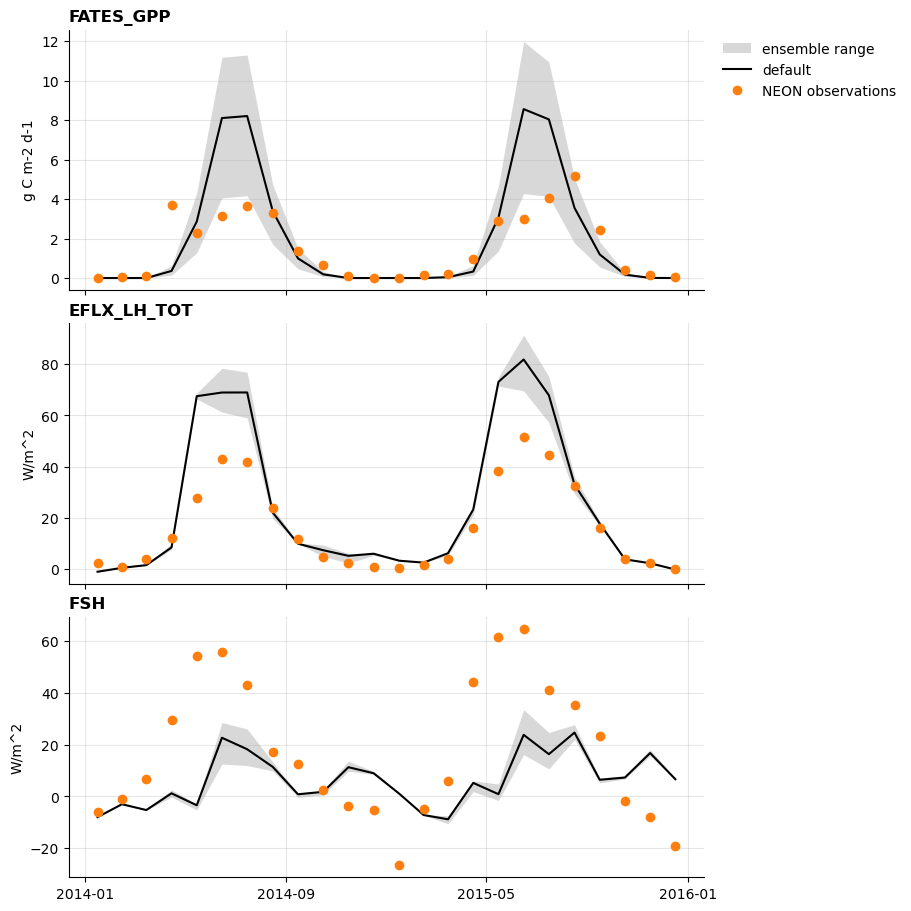

In [121]:
plot_obs_comparison(ensemble, default, obs, compare_vars)

The shaded range tells us whether any member reaches the observations. Let's compare each ensemble member:

In [173]:
def plot_obs_comparison_by_member(ensemble, default, obs, variables, parameters):
    """Plot the ensemble min and max, the default run, and observations for each variable."""

    colors = dict(zip(parameters, plt.cm.tab10.colors))
    
    fig, axes = plt.subplots(len(variables), 1, figsize=(9, 3 * len(variables)),
                             sharex=True, layout="constrained")
    
    for ax, variable in zip(np.atleast_1d(axes), variables):
        for param in parameters:
            lo = ensemble[variable].sel(member=get_member(manifest, param, "minimum"))
            hi = ensemble[variable].sel(member=get_member(manifest, param, "maximum"))
            lo.plot(ax=ax, color=colors[param], linestyle='--')
            hi.plot(ax=ax, color=colors[param], label=param)
        
        default[variable].plot(ax=ax, color="gray", lw=1.5, label="default")
        obs[variable].plot(ax=ax, color="black", marker="o", ls="",
                           markeredgecolor='white', zorder=5, ms=6,
                           label="NEON observations")

        ax.set_title(variable, loc="left", fontweight="bold")
        ax.set_xlabel("")
        ax.set_ylabel(default[variable].attrs.get("units", ""))
        ax.grid(alpha=0.3)
        ax.spines[["top", "right"]].set_visible(False)

    handles, labels = np.atleast_1d(axes)[0].get_legend_handles_labels()
    handles += [Line2D([], [], color="k", lw=1, ls="-"), Line2D([], [], color="k", lw=1, ls="--")]
    labels += ["maximum", "minimum"]
    fig.legend(handles, labels, frameon=False, loc="outside right center")

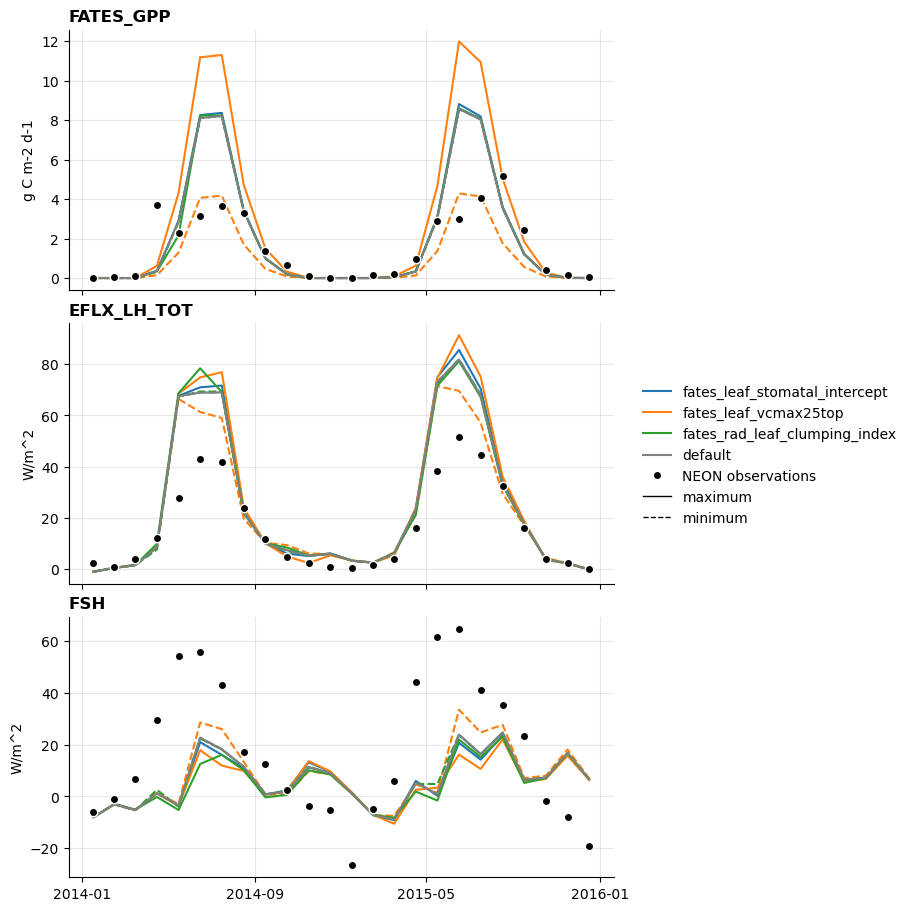

In [174]:
plot_obs_comparison_by_member(ensemble, default, obs, compare_vars, parameters)

<div class="alert alert-info">
<strong>Interpretation exercise 7</strong><br><br>

<ol>
<li>Do the observations fall inside the ensemble range? In which months and for which variables do they
not?</li>
<li>Which parameter, changed in which direction, moves the model closest to the observed summer GPP? Does that
same change improve latent and sensible heat?</li>
</ol>
</div>

<div class="alert alert-success">
<details>
<summary><font face="Times New Roman" color='blue'>Click here for the solution</font></summary><br>

<ol>
<li><strong>Mostly no.</strong> In midsummer, observed GPP is near the <em>bottom</em> of the range, observed
latent heat is <em>below</em> it, and observed sensible heat is well <em>above</em> it. The default run
produces about too much summer GPP, and too much latent heat, and not enough sensible heat.</li><br>

<li><strong>Lowering <code>fates_leaf_vcmax25top</code></strong> brings summer GPP close to the observations. It also moves latent and sensible heat in the right direction, but not far enough.
</details>
</div>

## Wrap up

You now know how to use the meristem package to perform a parameter sensitivity experiment. You can use this tool to investigate any parameter's influence on any process. There are several directions you might want to go next depending on your research project. 
* You might test whether a parameter's response is non-linear by running additional settings beyond the minimum and maximum, or using the Morris sampling method (a built in option in the meristem package). 
* You can investigate parameter interactions by modifying multiple parameters at the same time, or running a Sobol sensitivity experiment. 
* Once you understand which parameters are most influential on the processes you are interested in, you can select a subset to calibrate. 

To use an emulator based calibration method, the next step will be to run a latin hypercube sample. 
* Meristem has a built in latin hypercube sampling design.
* A rule of thumb for training an emulator is to start with 10xN ensemble members where N is the number of parameters. 
* There are many different emulator based calibration methods, we recommend starting with the [ESEm package](https://github.com/duncanwp/ESEm).

<div class="alert alert-info">
<strong>Challenge exercise</strong><br><br>

<ol>
<li>Run another PPE using a Latin hypercube sampling design with these three parameters. </li>

<li>For more information, look at the meristem [docs/paramgen.md](https://github.com/adrifoster/meristem/blob/main/docs/paramgen.md)  </li>

</ol>
</div>